<a class="anchor" id="0"></a>
# **Mubileum Duration Generation with VAE**

<a class="anchor" id="0.1"></a>
# **Table of Contents**

- 1. [Setup](#1)
- 2. [Data Preparation](#2)
<!--     - 2.1 [Data Preparation for LSTM](#2.1) -->
- 3. [EDA](#3)
- 4. [Anomaly Detection](#4)
- 5. [Anomaly Creation](#5)
- 6. [Genetic Algoritm Otimization](#6)


# **1. SetUp** <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
# Data Manipulation and Analysis
import numpy as np
import pandas as pd

#Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn for Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay


# TensorFlow and Keras for Deep Learning
# import tensorflow as tf
# from tensorflow.keras.models import Model
# from tensorflow.keras.layers import Input, LSTM, Dense, Lambda, RepeatVector
# from tensorflow.keras import backend as K


from sklearn.metrics import precision_recall_curve


# Read a CSV file into a Pandas DataFrame
df = pd.read_csv("/kaggle/input/mobileum/jul_aug_sep_oct_2022_msc_1.csv", sep=";")

# Convert Start Date and Start Hour into a datetime object and set as index
df['TIMESTAMP'] = pd.to_datetime(df['Start Date'] + ' ' + df['Start Hour'].astype(str), format='%d/%m/%Y %H')
# df.set_index("TIMESTAMP", inplace=True)

# Clean the #Events column, remove any non-numeric characters, fill NaNs with 0, and convert to integer
df['#Events'] = df['#Events'].str.replace(r'[^\d.-]', '', regex=True)
df['#Events'] = df['#Events'].fillna(0)
df['#Events'] = pd.to_numeric(df['#Events']).astype(int)

# Drop unnecessary columns
# df.drop(columns=['Datasource', 'Start Date', 'Start Hour'], inplace=True) 
df.drop(columns=['Datasource', 'Start Date', 'Start Hour', 'Event Duration'], inplace=True)

# Drop duplicates
df.drop_duplicates(inplace=True)
# df=df.reset_index()

In [2]:
df

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,TIMESTAMP
0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105,2022-07-18 00:00:00
1,VOICE,CALL FORWARD,Application,INT,NOT-ROAMING,P_0001,16,2022-07-18 00:00:00
2,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0002,7,2022-07-18 00:00:00
3,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0003,15,2022-07-18 00:00:00
4,VOICE,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0004,1,2022-07-18 00:00:00
...,...,...,...,...,...,...,...,...
958783,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0280,30,2022-10-13 21:00:00
958784,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0079,265,2022-10-13 21:00:00
958785,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0102,6,2022-10-13 21:00:00
958786,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0022,3,2022-10-13 21:00:00


# Get all combinations of aggregation

# **4. Anomaly Creation** <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [3]:
def filter_and_aggregate(df, filter_conditions, hierarchy=False):
    """
    Filters the DataFrame based on given conditions and aggregates by summing up a specified column.
    
    Args:
    - df: The original DataFrame.
    - filter_conditions: A dictionary where keys are column names and values are the values to filter on.
    
    Returns:
    - A new DataFrame with the filtered and aggregated data.
    """
    # Apply the filter conditions
    df_fil = df.copy()
    
    for col, val in filter_conditions.items():
        df_fil = df_fil[df_fil[col] == val]
    
    # Drop the columns used for filtering
    df_fil.drop(columns=list(filter_conditions.keys()), inplace=True)
    
    # Group by 'TIMESTAMP' and sum up the '#Events' column
    if hierarchy:
        df_agg = df_fil.groupby('TIMESTAMP')[['#Events','Anomaly']].sum().reset_index()
    else:
        df_agg = df_fil.groupby('TIMESTAMP')['#Events'].sum().reset_index()
    
    return df_agg


In [4]:
def generate_anomaly(mean, std, lower_bound=0):
    """
    Generate a random anomaly value.
    
    Parameters:
    mean (float): The mean value of the normal data.
    std (float): The standard deviation of the normal data.
    lower_bound (int): The minimum value an anomaly can take, inclusive. Default is 0.
    
    Returns:
    int: An anomalous data point.
    """
    upper_normal = mean + 3 * std
    lower_normal = max(mean - 3 * std, lower_bound)
    
    
    # Choose between an anomaly below or above the normal range.
    anomaly_value = np.random.choice([upper_normal, lower_normal])
    return anomaly_value


In [5]:
def insert_anomaly(df, df_anomaly, index, unique_conditions, plot=False):
    # Identify time-stamp at the given index
    ts = df_anomaly.iloc[index]['TIMESTAMP']
    
    # Define window for calculating std and mean
    start = max(index - 84, 0)
    end = min(index + 83, len(df_anomaly) - 1)
    
    # Calculate standard deviation and mean within the window
    std = df_anomaly[start:end]['#Events'].std()
    mean = df_anomaly[start:end]['#Events'].mean()
    
    # Generate anomaly value
    anomaly_value = generate_anomaly(mean, std)

    
    mask = (df['TIMESTAMP'] == ts)

    # Apply additional conditions from dictionary of conditions
    for col, val in unique_conditions.items():
        mask &= (df[col] == val)

    # This mask can now be used to filter df
    rows_with_ts = df[mask]

    # Sum of '#Events' for these rows
    sum_events = rows_with_ts['#Events'].sum()

    # Calculate multiplier
    m = anomaly_value / sum_events

    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df.columns:
        df['Anomaly'] = 0
    

    # Apply multiplier and round to integer values
    df.loc[mask, '#Events'] = (rows_with_ts['#Events'] * m).round().astype(int)

    # Update 'Anomaly' column only for rows where '#Events' 
    df.loc[mask, 'Anomaly'] = 1
    
    
    if plot == True:
        print(f"Anomaly value: {anomaly_value}")
        plt.figure(figsize=(10, 6))
        plt.plot(df_original["TIMESTAMP"], df_original["#Events"], label="Events", marker='o', linestyle='-', markersize=4)
        plt.scatter(ts, anomaly_value, color='red', s=100, label='Anomaly', zorder=5)
        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()


    # Print actual and anomaly values
    actual_value = df_anomaly.iloc[index]['#Events']
    anomaly_value_df = df.loc[mask, '#Events'].sum()
    print("actual_value:", actual_value, "Anomaly_value:", anomaly_value,"Anomaly_value_df:", anomaly_value_df, "Mean:", mean, "Std:", std)
    
    return ts, mean, std, anomaly_value, anomaly_value_df, actual_value, unique_conditions

In [6]:
def insert_nanomaly(df, n_anomalies, plot=False):
    
    columns = ['Call Type', 'Event Type', 'Subscriber Type', 'Traffic Type', 'Service Type', 'Partner Description']
    
    # Store anomalies for plotting
    anomaly_records = []
    
    # Store unique conditions to ensure they are not repeated
    used_conditions = set()
    
    df_anomaly = df.copy()
    
    # Check if the 'Anomaly' column exists
    if 'Anomaly' not in df_anomaly.columns:
        df_anomaly['Anomaly'] = 0
    
    for _ in range(n_anomalies):
            while True:
                # Ensure that the same new_columns and unique_conditions are not generated again
                new_columns = [col for col in columns if random.random() < 0.5]
                unique_conditions = {col: random.choice(df[col].unique()) for col in new_columns}
                conditions_tuple = tuple(sorted(unique_conditions.items()))  # Need to convert to a hashable type to store in a set

                if conditions_tuple not in used_conditions:
                    
                    df_fil = filter_and_aggregate(df, unique_conditions)

                    # Retry if df_fil is empty, otherwise, break the loop
                    if not df_fil.empty:
                        used_conditions.add(conditions_tuple)
                        index = random.choice(df_fil.index)
                        ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions = insert_anomaly(df_anomaly, df_fil, index, unique_conditions, plot=False)
                        anomaly_records.append((ts, mean, std, anomaly_value, anomaly_value_df, actual_value, conditions))
                        break  # Successfully inserted an anomaly, can exit loop
                    else:
                        print("This aggregation is empty, retrying with new unique conditions.")
    
    
    anomalies_info_df = pd.DataFrame(anomaly_records, columns=['TIMESTAMP', 'Mean', 'STD', 'Anomaly Value', 'Anomaly Value from DF', 'Actual Value', 'Used Conditions'])

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(df_anomaly["TIMESTAMP"], df_anomaly["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

        # Extract timestamps and anomaly values for plotting
#         ts_values, anomaly_values = zip(*anomaly_records) if anomaly_records else ([], [])
        plt.scatter(anomalies_info_df["TIMESTAMP"], anomalies_info_df["Anomaly Value"], color='red', s=100, label='Anomaly', zorder=5)

        plt.xlabel('TIMESTAMP')
        plt.ylabel('#Events')
        plt.title('Visualization of #Events with Anomaly Inserted')
        plt.legend()
        plt.grid(True)
        plt.show()
    
#     ?<create a dataframe which store the (ts, mean, std, anomaly_value, anomaly_value_df, actual_value and used_conditions)
    

    # Optional: print out the anomaly records for debugging
#     print(anomaly_records)
    
    return df_anomaly, anomalies_info_df


1. get the anomaly_value and the ts with the function. 
2. go to the original df get all the rows with the same ts (TIMESTAMP)
3. from all the row calculate the sum of column (#Events)
4. calculate the multiplier witch m = anomaly_value/ sum of column (#Events)
5. use the multiplier to all rows of the #Events and do the round to get int
6. Create an new columns witch name "Anomaly" with 0 or 1, which all row which has column 
7. gerate an orignal and modified df

actual_value: 21330 Anomaly_value: 44179.073859747536 Anomaly_value_df: 44179 Mean: 15633.98347107438 Std: 9515.03012955772
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
This aggregation is empty, retrying with new unique conditions.
actual_value: 30026 Anomaly_value: 0.0 Anomaly_value_df: 0 Mean: 51072.16766467066 Std: 32565.160486351662
This aggregation is empty, retrying with new unique conditions.
actual_value: 1 Anomaly_value: 5.516800354185154 Anomaly_value_df: 6 Mean: 1.6666666666666667 Std: 1.2833778958394957
This aggregation is empty, retrying with new unique conditions.
actual_value: 290596 Anomaly_value: 0.0 Anomaly_value_df: 0 Mean: 204350.73053892216 Std: 110646.48656116726
actual_value: 17340 Anomaly_va

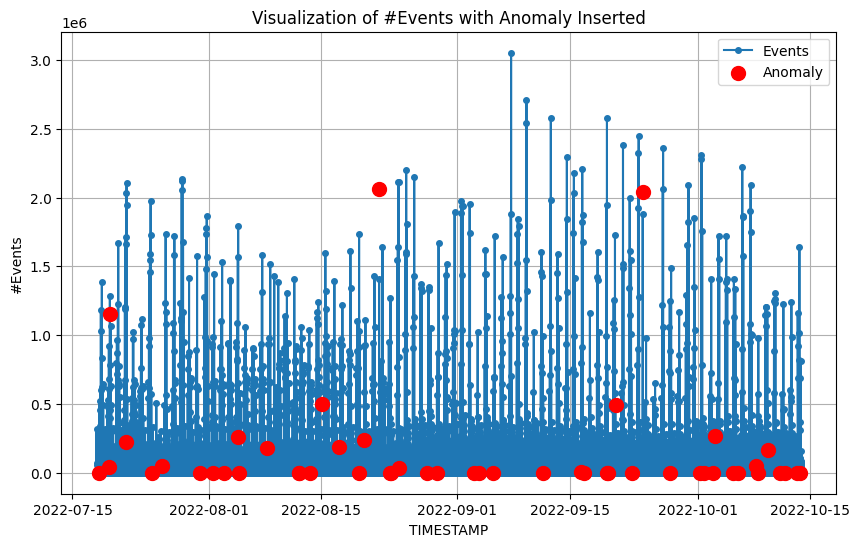

In [7]:
import random

random.seed(41)
df_anomaly, df_info = insert_nanomaly(df, 50, plot=True)

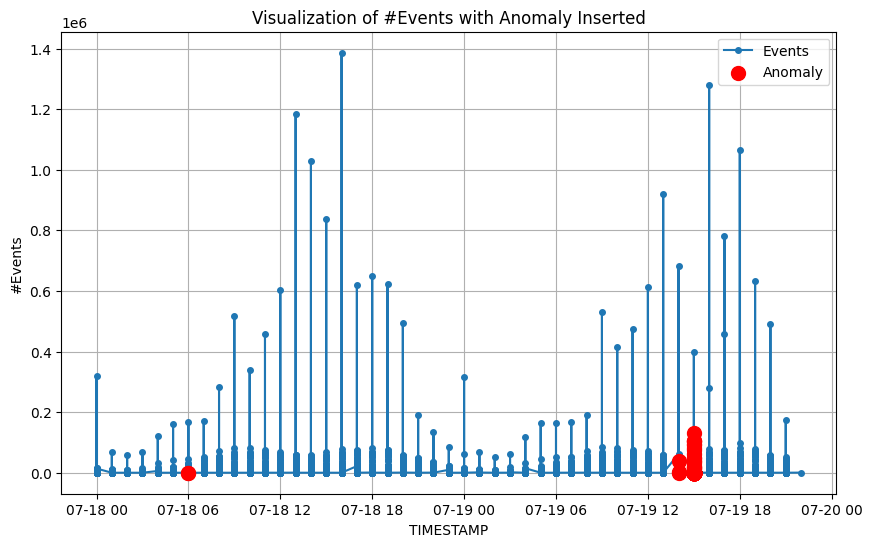

In [8]:
start=0
end=20000


aux = df_anomaly[start:end]

indexes = aux[aux["Anomaly"]==1].index
plt.figure(figsize=(10, 6))

plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

# Destacando o valor anômalo
plt.scatter(aux.iloc[(indexes-start).values]["TIMESTAMP"], aux["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)

plt.xlabel('TIMESTAMP')
plt.ylabel('#Events')
plt.title('Visualization of #Events with Anomaly Inserted')
plt.legend()
plt.grid(True)
plt.show()

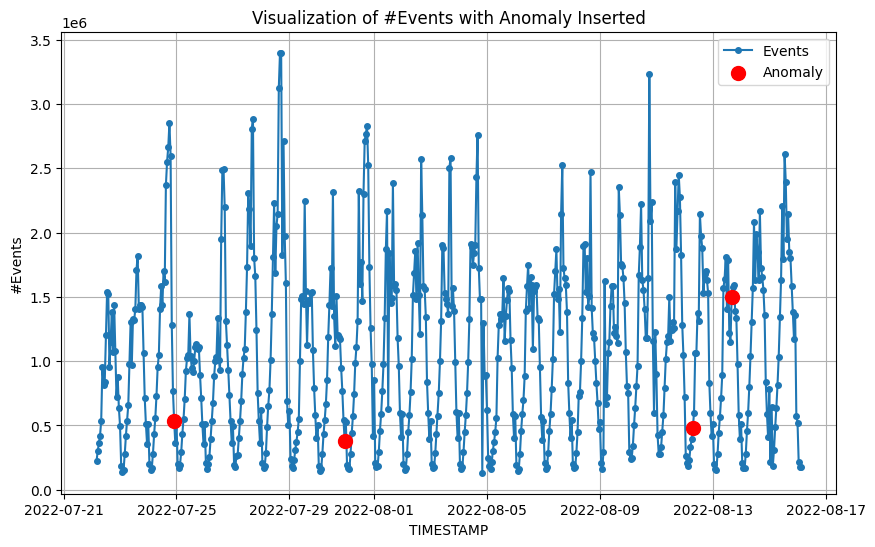

In [9]:
start=100
end=700

aux = filter_and_aggregate(df_anomaly, {}, True)

aux = aux[start:end]
indexes = aux[aux["Anomaly"]==1].index
plt.figure(figsize=(10, 6))

plt.plot(aux["TIMESTAMP"], aux["#Events"], label="Events", marker='o', linestyle='-', markersize=4)

# Destacando o valor anômalo
plt.scatter(aux.iloc[(indexes-start).values]["TIMESTAMP"], aux["#Events"][indexes], color='red', s=100, label='Anomaly', zorder=5)

plt.xlabel('TIMESTAMP')
plt.ylabel('#Events')
plt.title('Visualization of #Events with Anomaly Inserted')
plt.legend()
plt.grid(True)
plt.show()

# 5. Hierarchical Structure

In [10]:
def set_leaf(df):
    df['Anomaly'] = df['Anomaly'].apply(lambda x: 1 if x > 0 else x)
    
    # Define start and end timestamps
    start = '2022-07-18 00:00:00'
    end = '2022-10-13 21:00:00'
    
    # Generate the timestamp range at 1-hour intervals
    timestamp_range = pd.date_range(start=start, end=end, freq='h')
    
    # Create the DataFrame
    df_default = pd.DataFrame({
        'TIMESTAMP': timestamp_range,
        '#Events': 0,
        'Anomaly': 0
    })
    
    df_default.loc[df_default["TIMESTAMP"] == df["TIMESTAMP"], df.columns[1:]] = df.iloc[:, 1:].values

    return df_default


In [11]:


# Define the filter conditions for each leaf in the hierarchy
filter_conditions_leaves = [
    {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'TERMINATED'},
    {'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'ORIGINATED'},
    {'Call Type': 'SMS', 'Subscriber Type': 'Roamer In'}
]

# Use the function filter_and_aggregate to aggregate for every leaf and store the dataframes
aggregated_df = {}

for i, conditions in enumerate(filter_conditions_leaves, start=1):
    print(conditions)
    agg_df = filter_and_aggregate(df_anomaly, conditions, hierarchy=True)
    print(agg_df)
    agg_df = set_leaf(agg_df)
    
    aggregated_df[f'leaf_{i}'] = agg_df

# output the keys of the aggregated_dataframes dictionary to confirm the storage
aggregated_df.keys()


{'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'TERMINATED'}
               TIMESTAMP  #Events  Anomaly
0    2022-07-18 00:00:00   383772        0
1    2022-07-18 01:00:00   106005        0
2    2022-07-18 02:00:00    92578        0
3    2022-07-18 03:00:00    96438        0
4    2022-07-18 04:00:00   173724        0
...                  ...      ...      ...
2105 2022-10-13 17:00:00   888471        0
2106 2022-10-13 18:00:00   567088        0
2107 2022-10-13 19:00:00   494233        0
2108 2022-10-13 20:00:00   945266        0
2109 2022-10-13 21:00:00   234887        0

[2110 rows x 3 columns]
{'Call Type': 'SMS', 'Service Type': 'NOT-ROAMING', 'Event Type': 'ORIGINATED'}
               TIMESTAMP  #Events  Anomaly
0    2022-07-18 00:00:00     1381        0
1    2022-07-18 01:00:00      935        0
2    2022-07-18 02:00:00      716        0
3    2022-07-18 03:00:00      648        0
4    2022-07-18 04:00:00      780        0
...                  ...      ...      ..

dict_keys(['leaf_1', 'leaf_2', 'leaf_3'])

# **5. Anomaly Detetion** <a class="anchor" id="5"></a>

[Table of Contents](#0.1)

1. label das anomalias
2. hierarquia fixa, calcular Matrix P
3. Optimizacao S

Como a Criacao de janelas series temporais relaciona-se com o seguintes:
Hierarquias
Detecao de anomalias
agoritmos genericos

Matrix Profile
Mais tarde: Pyod (outlier detection)

Distancia minima
AUC (‘threshold’)

## Ao aumentar o quartile a anomalia restringe aos valores dos eventos com duracao excessiva, apesar da duranca aumentar com o tempo seguindo uma periodicidade semanal

verificar as anomalias serem iguais entre os dois colunas ja que tem o mesmo numero de anomalias do Event Duration and #Events

## 5.1 Statistical Thresholding

In [12]:
def create_features(data, window_size):
    X = []
    y = []
    for i in range(len(data) - window_size):
        X.append(data.iloc[i:i+window_size].drop(columns=['Anomaly']).values.flatten())
        y.append(data.iloc[i+window_size]['Anomaly'])
    return np.array(X), np.array(y)


def plot_confusion_matrix(y_true, y_pred, labels=None, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()
    
    
def sliding_window_auc(window_size, df, plot=False):
    # Convert TIMESTAMP to datetime and sort
    data = df.set_index("TIMESTAMP")


    # Split into train and test sets
    X, y = create_features(data, window_size)
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)
    # Train the Logistic Regression model
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    # Get predicted probabilities for the positive class
    probabilities = model.predict_proba(X_test)[:, 1]

    # Compute AUC
    auc_score = roc_auc_score(y_test, probabilities)

    if plot:
        # Use the predictions, not the probabilities, to plot the confusion matrix
        y_pred = model.predict(X_test)
        plot_confusion_matrix(y_test, y_pred)
    
    return auc_score

In [13]:
def HTS_auc(aggregated_df, window_size):

    auc_scores = {}

    # Loop through each aggregated DataFrame
    for leaf_name, df_leaf in aggregated_df.items():
        auc_score = sliding_window_auc(window_size, df=df_leaf, plot=True)  # Or window_size=24
        auc_scores[leaf_name] = auc_score

    auc_score_mean = sum(auc_scores.values()) / len(auc_scores)
    
    return auc_score_mean

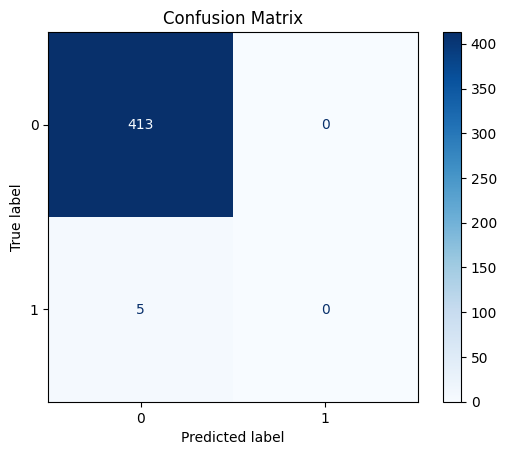

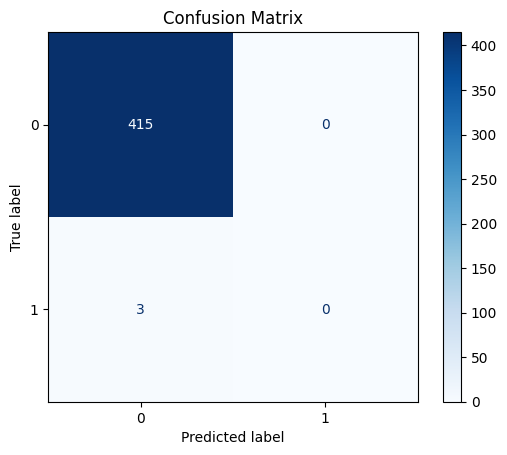

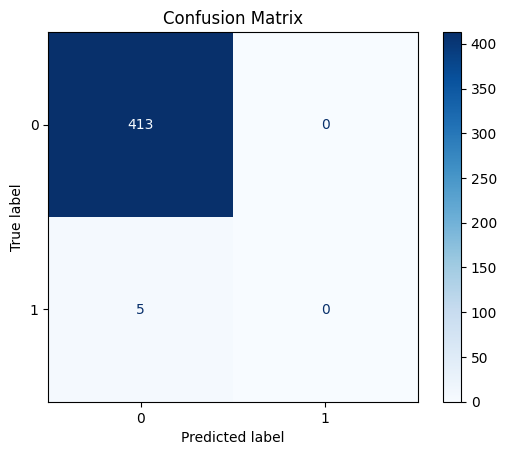

0.6845467422555437

In [14]:
HTS_auc(aggregated_df, 24)

As hierarquias so entram aqui nesta fase?
as anomalias agregam, so basta ter um dos valores da juncao positiva para ser anomalia

Amostragem aleatória das hierarquias
Definir população inicial
Como fazer as mutações

Genetic Programing

Ex: 
 > Comocar com 100 aleatorias e avaliamos o fitness (F1 score)
 > > 100 hieraquias aleatorias
 > Escolher as 20 melhores e fazer multacoes ate termos uma nova populacao de 100 
 > Paragem:
 > > O melhor F1 score da populacao nao aumenta mais que 1%
 > >
